# Looking to change in temperature

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import medfilt, detrend
import glob
import os
import xarray as xr
from tqdm import tqdm
from matplotlib.colors import PowerNorm

In [21]:
plot_dir = '../../plots/FBG_Temperature'
if not os.path.exists(plot_dir):
    os.makedirs(plot_dir)

## Comparison FBG ERA5

In [22]:
dw = xr.open_dataset('../../data/weather/t2m_gunnuvher_era5_2024-08-01_to_2025-10-01.nc')

In [23]:
dw

<xarray.Dataset> Size: 287kB
Dimensions:     (valid_time: 10248)
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 82kB 2024-08-01 ... 2025-10-01T23...
    expver      (valid_time) <U4 164kB ...
Data variables:
    t2m         (valid_time) float32 41kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-11-21T15:04 GRIB to CDM+CF via cfgrib-0.9.1...

## Channel 2 (Python : Channel 1)

In [24]:
df = xr.open_dataset('../../../fbg_data_r/gunnvher_channel_1_fbg_cleaned_1h.nc')

In [25]:
dw = dw.sel(valid_time=df.Time)

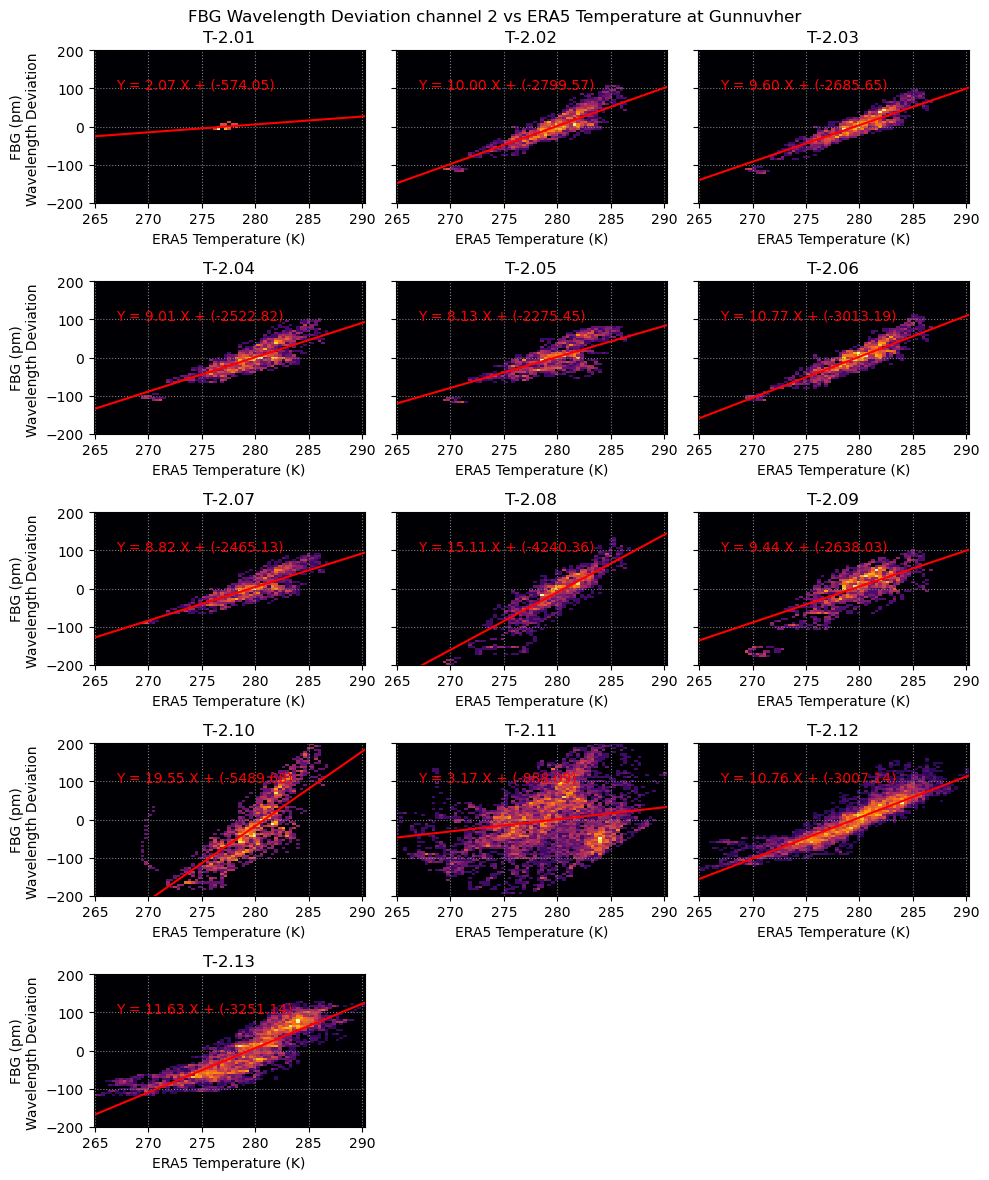

In [27]:
fig, ax = plt.subplots(figsize=(10,12), nrows=5, ncols=3, sharey=True)
for fbg in range(15) :

    row = fbg // 3
    col = fbg % 3
    if fbg >= 13 :
        ax[row, col].set_axis_off()
        continue
    df_ = df.sel(FBG=fbg).dropna('Time')
    if col == 0 :
        ax[row, col].set_ylabel('FBG (pm)\nWavelength Deviation ')
    #ax[row, col].scatter(dw.sel(Time=df_.Time, method='nearest').t2m, df_.Wavelength_nm - df_.Wavelength_nm.mean(), s=1)
    data = (df_.Wavelength_nm - df_.Wavelength_nm.mean()) *1000
    per_5, per_95 = np.percentile(data, [5,95])
    train_data = np.extract((data > per_5) & (data < per_95), data)
    train_time = np.extract((data > per_5) & (data < per_95), dw.sel(Time=df_.Time, method='nearest').t2m)
    m,x = np.polyfit(train_time, train_data, 1)
    #m,x = np.polyfit(dw.sel(Time=df_.Time, method='nearest').t2m, train_data, 1)

    ax[row, col].plot(np.linspace(np.min(dw.t2m), np.max(dw.t2m),10), 
         m*np.linspace(np.min(dw.t2m), np.max(dw.t2m),10) + x, c='r')
    ax[row, col].text(267, 100, 'Y = {:.2f} X + ({:.2f})'.format(m, x),c='r')

    plot = ax[row, col].hist2d(dw.sel(Time=df_.Time, method='nearest').t2m, (df_.Wavelength_nm - df_.Wavelength_nm.mean()) *1000,
                         bins=75, range=[[dw.t2m.min(), dw.t2m.max()], [-200, 200]], density = True, cmap='inferno', norm=PowerNorm(0.5),)
    ax[row, col].grid(ls=':', c='grey')
    ax[row, col].set_xlim(dw.t2m.min(), dw.t2m.max())
    ax[row, col].set_ylim(-200, 200)
    ax[row, col].set_title('T-2.%02i' % (fbg+1))
    ax[row, col].set_xlabel('ERA5 Temperature (K)')
#fig.colorbar(mappable=plot[3], label='Density', location='right', shrink=0.6)
plt.suptitle('FBG Wavelength Deviation channel 2 vs ERA5 Temperature at Gunnuvher')
plt.tight_layout()
plt.savefig(plot_dir + '/era_5_vs_fbg.png', dpi=300, bbox_inches='tight')
plt.show()

## Temperature profile : Channel 2, 4 & 6

In [29]:
df_ch2 = xr.open_dataset('../../../fbg_data_r/gunnvher_channel_1_fbg_cleaned_1h.nc')
df_ch2['FBG'] = 200 + df_ch2.FBG.values

In [31]:
df = xr.open_dataset('../../../fbg_data_r/gunnvher_channel_4_fbg_cleaned_10s.nc')
df_2 = xr.open_dataset('../../../fbg_data_r/gunnvher_channel_6_fbg_cleaned_10s.nc')
temp_arr_ = np.array([df.Wavelength_nm.sel(FBG=slice(4,9)).values,df_2.Wavelength_nm.sel(FBG=slice(0,5)).values])
temp_arr_ = np.nansum(temp_arr_, axis=0)
temp_arr_ = np.where(temp_arr_==0, np.nan, temp_arr_)

df['Wavelength_nm'][:,4:9] = temp_arr_
#df.Wavelength_nm.plot()
df = df.resample(Time='1h').mean()

df['FBG'] = 400 + df.FBG.values #Channel 4 FBGs renumbered to avoid overlap with channel 2

In [32]:
ch5 = xr.open_dataset('../../../fbg_data_r/gunnvher_channel_5_fbg_cleaned_10s.nc')
ch5['Wavelength_nm'] = ch5.Wavelength_nm - ch5.Wavelength_nm.mean(dim='Time')
ch5['Wavelength_10pm'] = ch5.Wavelength_nm * 1000/10

In [33]:
df = xr.concat([df_ch2, df], dim='FBG')
df['Wavelength_nm'] = df.Wavelength_nm - df.Wavelength_nm.mean(dim='Time')
df['Wavelength_10pm'] = df.Wavelength_nm *1000/10

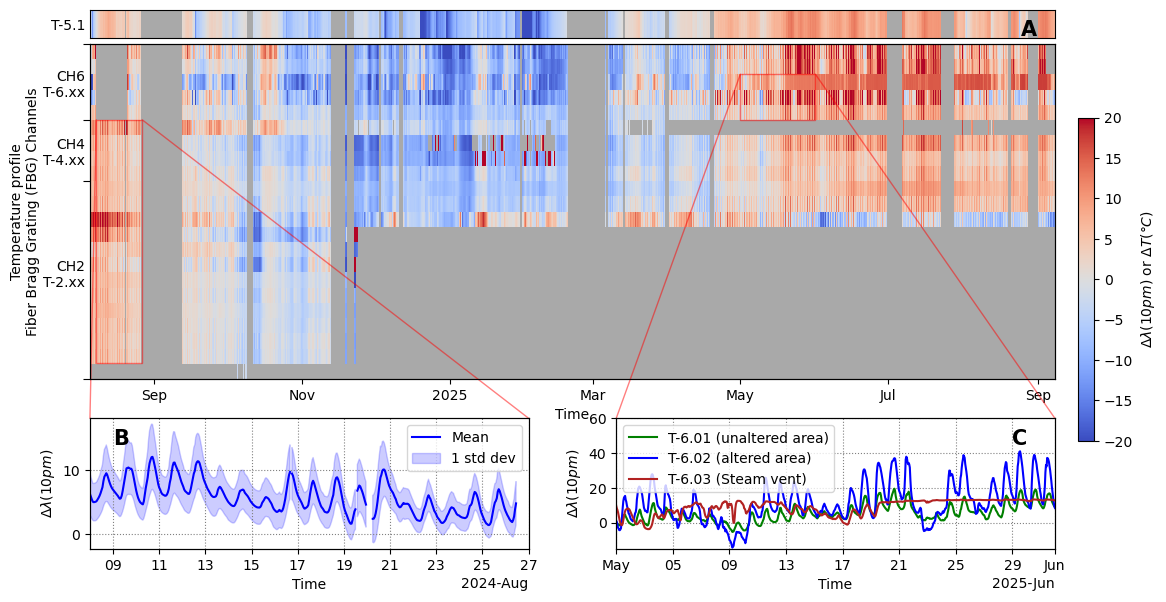

In [34]:
fig = plt.figure(figsize=(15,7))

ax_ch5 = plt.subplot2grid((16,2), (0,0), colspan=2)
ch5_T, ch5_D = np.meshgrid(ch5.Time, [0,1])
ax_ch5.imshow([ch5.Wavelength_10pm.sel(FBG=0).values,ch5.Wavelength_10pm.sel(FBG=0).values], 
                  cmap='coolwarm', vmin=-20, vmax=20, interpolation='none', aspect='auto')
ax_ch5.set_facecolor('darkgray')
ax_ch5.set_yticks([.5], ['T-5.1'])
ax_ch5.set_xticks([], [])
ax_ch5.tick_params(axis='y', length=0)
ax = plt.subplot2grid((16,2), (1,0), rowspan=10, colspan=2)



df['FBG_label'] = df.FBG.values
df['FBG'] = np.arange(len(df.FBG))
df.Wavelength_10pm.plot.imshow(ax=ax, x='Time', y='FBG', 
                               cmap='coolwarm', vmin=-20, vmax=20, add_colorbar=False)# cbar_kwargs={"label": "Wavelength shift (10*pm)\nTemperature change (°C)"})
ax.set_xlabel('Time')

ax.set_yticks([-.5,12.5,16.5,21.5], ['','','',''])
ax.tick_params(axis='y', length=5)
axb = ax.twinx()
axb.tick_params(axis='y', left=True, labelleft=True, right=False, labelright=False,length=2)
axb.set_ylim(bottom=-.5, top=21.5)
axb.set_yticks([6.5,14.5,19], labels=['CH2\nT-2.xx', 'CH4\nT-4.xx', 'CH6\nT-6.xx'])
axb.tick_params(axis='y', length=0)
ax.set_ylabel('Temperature profile\nFiber Bragg Grating (FBG) Channels\n\n')
ax.set_ylim(top=21.5)
#plt.yticks([205,210,215,400,405], ['Ch2 FBG 5', 'Ch2 FBG 10', 'Ch2 FBG 15', 'Ch4 FBG 5', 'Ch4 FBG 10'])
ax.set_facecolor('darkgray')
ax1 = plt.subplot2grid((16,2), (12,0), colspan=1, rowspan=4)

std = (df.Wavelength_10pm.sel(FBG=slice(1,16), Time=slice('2024-08-08', '2024-08-27'))).std(dim='FBG')
mean = (df.Wavelength_10pm.sel(FBG=slice(1,16), Time=slice('2024-08-08', '2024-08-27'))).mean(dim='FBG')
#(df.Wavelength_10pm.sel(FBG=slice(1,8), Time=slice('2024-08-08', '2024-08-27'))).mean(dim='FBG').plot(ax=ax1)
mean.plot(ax=ax1, color='blue', label='Mean')
ax1.fill_between(mean.Time, mean-std, mean+std, color='blue', alpha=0.2, label='1 std dev')
ax1.set_title('')
ax1.set_xlim(np.datetime64('2024-08-08'), np.datetime64('2024-08-27'))
ax1.grid(ls=':', c='grey')
ax1.set_ylabel('$\Delta\lambda (10 pm)$')
ax1.legend(loc='upper right')
ax1b = ax1.twinx()
ax1b.set_ylim(.5,16.5), ax1b.set_xlim(np.datetime64('2024-08-08'), np.datetime64('2024-08-27'))
ax1b.tick_params(axis='y', left=False, labelleft=False, right=False, labelright=False,length=2)
#ax1b.set_yticks([0],[''])
#ax1.set_ylim
ax.indicate_inset_zoom(ax1b, edgecolor="r")
ax2 = plt.subplot2grid((16,2), (12,1), colspan=1, rowspan=4)
ch6_1 = df.Wavelength_10pm.sel(FBG=18, Time=slice('2025-05-01', '2025-06-01'))
ch6_2 = df.Wavelength_10pm.sel(FBG=19, Time=slice('2025-05-01', '2025-06-01'))
ch6_0 = df.Wavelength_10pm.sel(FBG=17, Time=slice('2025-05-01', '2025-06-01'))

#ch6_1.plot(ax=ax2, color='blue', label='Channel 6 FBG 2')
#ch6_2.plot(ax=ax2, color='firebrick', label='Channel 6 FBG 3 (Steam vent)')
#ch6_0.plot(ax=ax2, color='green', label='Channel 6 FBG 1')

ch6_0.plot(ax=ax2, color='green', label='T-6.01 (unaltered area)')
ch6_1.plot(ax=ax2, color='blue', label='T-6.02 (altered area)')
ch6_2.plot(ax=ax2, color='firebrick', label='T-6.03 (Steam vent)')


ax2.set_ylim(-15,60)
ax2.legend(loc='upper left')
ax2b = ax2.twinx()
ax2b.set_ylim(16.5,19.5), ax2b.set_xlim(np.datetime64('2025-05-01'), np.datetime64('2025-06-01'))
ax2b.tick_params(axis='y', left=False, labelleft=False, right=False, labelright=False,length=2)
ax.indicate_inset_zoom(ax2b, edgecolor="r")
ax2.set_title('')
ax2.set_ylabel('$\Delta\lambda (10 pm)$')
ax2.grid(ls=':', c='grey')

ax.text(np.datetime64('2025-08-25'), 22, "A", fontsize=15, fontweight='bold', color='k')
ax1.text(np.datetime64('2024-08-09'), 14, "B", fontsize=15, fontweight='bold', color='k')
ax2.text(np.datetime64('2025-05-29'), 45, "C", fontsize=15, fontweight='bold', color='k')

fig.colorbar(ax.images[0], ax=[ax_ch5, ax, ax1, ax2], location='right', label='$\Delta\lambda (10 pm)$ or $\Delta T (°C)$', shrink=0.6, pad=0.02)
plt.savefig(plot_dir + '/FBG_temperature_sensors.png', dpi=300, bbox_inches='tight')
plt.show()